# Pickleball ladder day: is "winners up, losers down" fair?
**Question.** On a ladder day, players on each court play, winners move up a court and losers move down. After a few rounds, does the final ladder order match true skill? Would an Elo-style rating do better?

**Method.** A simulation. 24 players have a hidden skill. Each round, 6 courts of 4 players play; the top 2 on each court move up and the bottom 2 move down. I compare the final ladder order with the hidden skill, and with an Elo rating updated after every game. This is a simplified model, not data from a real event.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import spearmanr
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False})
rng = np.random.default_rng(630)
N_PLAYERS, N_COURTS, ROUNDS_MAX = 24, 6, 8

def win_prob(a, b):  # logistic win chance from skill gap
    return 1 / (1 + np.exp(-(a - b) / 0.6))

def run_event(skill, rounds, rng):
    order = rng.permutation(N_PLAYERS)  # start: random court assignment
    elo = np.full(N_PLAYERS, 1500.0)
    for _ in range(rounds):
        new_order = []
        courts = [order[i * 4:(i + 1) * 4] for i in range(N_COURTS)]
        winners_by_court, losers_by_court = [], []
        for c in courts:
            wins = {p: 0 for p in c}
            for a, b in [(0, 1), (2, 3), (0, 2), (1, 3), (0, 3), (1, 2)]:  # round robin of 4 (singles-style games)
                pa, pb = c[a], c[b]
                a_wins = rng.random() < win_prob(skill[pa], skill[pb])
                wins[pa if a_wins else pb] += 1
                exp_a = 1 / (1 + 10 ** ((elo[pb] - elo[pa]) / 400))
                elo[pa] += 24 * ((1 if a_wins else 0) - exp_a)
                elo[pb] += 24 * ((0 if a_wins else 1) - (1 - exp_a))
            ranked = sorted(c, key=lambda p: -wins[p])  # ties keep list order
            winners_by_court.append(ranked[:2]); losers_by_court.append(ranked[2:])
        # winners up one court (court 0 = top), losers down one court
        new_courts = [[] for _ in range(N_COURTS)]
        for i in range(N_COURTS):
            new_courts[max(i - 1, 0)] += winners_by_court[i]
            new_courts[min(i + 1, N_COURTS - 1)] += losers_by_court[i]
        # top and bottom courts keep 4 players by construction; others get 2 from below + 2 from above
        order = np.array([p for c in new_courts for p in c])
    return order, elo

## 1. One event: how close is the final order to true skill?

In [2]:
skill = rng.normal(0, 1, N_PLAYERS)
order, elo = run_event(skill, 5, rng)
ladder_rank_score = np.empty(N_PLAYERS); ladder_rank_score[order] = -np.arange(N_PLAYERS)  # higher = better court
rho_ladder = spearmanr(ladder_rank_score, skill).statistic
rho_elo = spearmanr(elo, skill).statistic
print(f"Spearman with true skill, ladder order: {rho_ladder:.2f}, Elo: {rho_elo:.2f}")

Spearman with true skill, ladder order: 0.85, Elo: 0.77


## 2. Repeat 300 events for 1 to 8 rounds
One event is noisy, so I run 300 of them at each number of rounds and average.

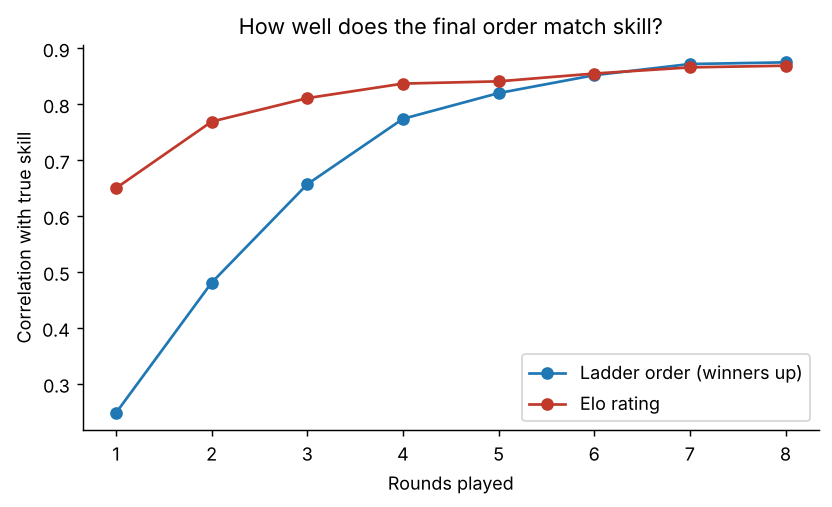

,rounds,ladder_order,elo
0,1,0.248,0.650
1,2,0.481,0.769
2,3,0.657,0.811
3,4,0.774,0.837
4,5,0.820,0.841
5,6,0.852,0.855
6,7,0.872,0.866
7,8,0.875,0.869


In [3]:
res = []
for rounds in range(1, ROUNDS_MAX + 1):
    lad, el = [], []
    for _ in range(300):
        sk = rng.normal(0, 1, N_PLAYERS)
        o, e = run_event(sk, rounds, rng)
        s = np.empty(N_PLAYERS); s[o] = -np.arange(N_PLAYERS)
        lad.append(spearmanr(s, sk).statistic); el.append(spearmanr(e, sk).statistic)
    res.append((rounds, np.mean(lad), np.mean(el)))
res = pd.DataFrame(res, columns=["rounds", "ladder_order", "elo"]).round(3)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(res.rounds, res.ladder_order, marker="o", label="Ladder order (winners up)")
ax.plot(res.rounds, res.elo, marker="o", label="Elo rating", color="#c0392b")
ax.set_xlabel("Rounds played"); ax.set_ylabel("Correlation with true skill")
ax.set_title("How well does the final order match skill?"); ax.legend()
plt.tight_layout(); plt.savefig("figures/fig1_ladder_vs_elo.png"); plt.show()
res

## 3. Takeaways
* More rounds helps both methods.
* With only 1 to 4 rounds, Elo matches skill much better (for example about 0.65 versus 0.25 after one round), because it uses every game result and starts rating players right away. The ladder needs several rounds before players have moved to the right court.
* By about 6 rounds the two are roughly equal, so a long ladder day sorts players well on its own.
* A practical use: on a short event, or when seeding the first round of the next event, use ratings from past results. Keep the simple "up and down" format for fun and for long days.

**Limits.** Simulation with an assumed win-probability curve and singles-style round robins. Real play has doubles partners, injuries, and no-shows. Treat the numbers as a model, not as evidence about any real ladder.